# EMQA_L1_sim_wn_ar_rw

**Simulated white noise, AR(1) and random walk with their sample ACF**

Energy Markets Quantitative Analysis (EMQA), Lecture 1 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L1/EMQA_L1_sim_wn_ar_rw/EMQA_L1_sim_wn_ar_rw.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

Simulation (concept only, labelled as such on the slide): white noise, a stationary AR(1) with phi = 0.9 and a random walk built from the same 500 standard normal shocks (seed 20261104), with their sample autocorrelation functions and the white-noise band.

**Data:** T = 500, N(0,1) shocks. **Source:** simulation, numpy, seed 20261104.

The numbers printed below are those on the slide; the tag `[key]` is their name in `lectures/L1/L1_numbers.json`.

In [2]:
import json
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}   # fixed colour per bidding zone
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
ZONE_LS = {'RO': '-', 'BG': '--', 'HU': '-.', 'DE_LU': ':'}
ZONES = ['RO', 'BG', 'HU', 'DE_LU']
ZONE_NAME = {'RO': 'Romania (OPCOM PZU)', 'BG': 'Bulgaria (IBEX)', 'HU': 'Hungary (HUPX)', 'DE_LU': 'Germany-Luxembourg'}
MON_EN = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
MON1 = ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D']


def legend_bottom(fig, ncol=4, y=0.0):
    """One legend centred under the axes, outside the plotting area."""
    handles, labels = [], []
    for ax in fig.axes:
        for h, l_ in zip(*ax.get_legend_handles_labels()):
            if l_ not in labels:
                handles.append(h)
                labels.append(l_)
    if handles:
        fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, y), frameon=False,
                   handlelength=2.0, columnspacing=1.2)


def fl(x, k=4):
    """Round as on the slides."""
    return None if x is None or np.isnan(float(x)) else round(float(x), k)


def d(ts):
    return pd.Timestamp(ts).strftime('%Y-%m-%d')


def show(key, label, value):
    """Print a number of the slide; [key] = its name in lectures/L1/L1_numbers.json."""
    print(f'{label} = {value}   [{key}]')

## Computation

In [3]:
from statsmodels.tsa.stattools import acf
rng = np.random.default_rng(20261104)
TS = 500
eps = rng.standard_normal(TS)
ar = np.zeros(TS)
for t in range(1, TS):
    ar[t] = 0.9 * ar[t - 1] + eps[t]
SIM = {'wn': eps, 'ar': ar, 'rw': np.cumsum(eps)}
for k, s in SIM.items():
    r = acf(s, nlags=30, fft=True)
    show(f'sim.{k}.acf1', f'{k}: sample ACF at lag 1', fl(r[1], 2))
    show(f'sim.{k}.acf10', f'{k}: sample ACF at lag 10', fl(r[10], 2))
show('sim.ar_theory_acf10', 'AR(1) theoretical ACF at lag 10 = 0.9^10', fl(0.9 ** 10, 2))

wn: sample ACF at lag 1 = -0.03   [sim.wn.acf1]
wn: sample ACF at lag 10 = 0.07   [sim.wn.acf10]
ar: sample ACF at lag 1 = 0.9   [sim.ar.acf1]
ar: sample ACF at lag 10 = 0.41   [sim.ar.acf10]
rw: sample ACF at lag 1 = 1.0   [sim.rw.acf1]
rw: sample ACF at lag 10 = 0.96   [sim.rw.acf10]
AR(1) theoretical ACF at lag 10 = 0.9^10 = 0.35   [sim.ar_theory_acf10]


## Chart

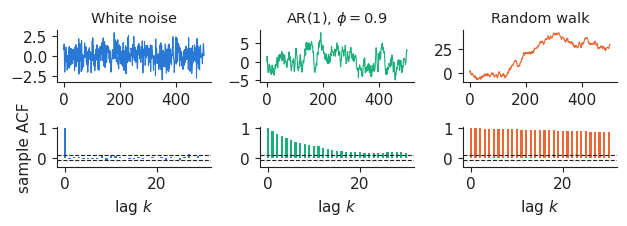

In [4]:
fig, axs = plt.subplots(2, 3, figsize=(6.4, 2.4), gridspec_kw={'height_ratios': [1.3, 1]})
for j, (k, col, ttl) in enumerate([('wn', PAL['RO'], 'White noise'), ('ar', PAL['HU'], 'AR(1), $\\phi=0.9$'),
                                   ('rw', PAL['DE_LU'], 'Random walk')]):
    axs[0, j].plot(SIM[k], color=col, lw=0.8)
    axs[0, j].set_title(ttl, fontsize=10.5)
    r = acf(SIM[k], nlags=30, fft=True)
    axs[1, j].bar(range(31), r, color=col, width=0.5)
    for sgn in (1, -1):
        axs[1, j].axhline(sgn * 1.96 / np.sqrt(TS), color='#222222', ls='--', lw=0.8)
    axs[1, j].set_ylim(-0.3, 1.05)
    axs[1, j].set_xlabel('lag $k$')
axs[1, 0].set_ylabel('sample ACF')
fig.tight_layout(rect=(0, 0.0, 1, 1))
plt.savefig('sim_wn_ar_rw.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()